In [8]:
import pandas as pd

# Load the CSV file into a Pandas DataFrame
df = pd.read_csv('Subscription Cohort Analysis Data.csv')

# Look at the first 5 rows
df.head()


,customer_id,created_date,canceled_date,subscription_cost,subscription_interval,was_subscription_paid
0,154536156,2022-09-01,NaN,39,month,Yes
1,149713408,2022-09-01,2022-09-02,39,month,No
2,153756284,2022-09-01,2022-09-02,39,month,No
3,121253113,2022-09-01,2022-09-23,39,month,Yes
4,154467210,2022-09-01,2023-06-29,39,month,Yes


In [9]:
# Check column names and data types
print(df.info())

# Check if there are any missing/blank values
print("\nMissing values count:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3069 entries, 0 to 3068
Data columns (total 6 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   customer_id            3069 non-null   int64 
 1   created_date           3069 non-null   object
 2   canceled_date          2004 non-null   object
 3   subscription_cost      3069 non-null   int64 
 4   subscription_interval  3069 non-null   object
 5   was_subscription_paid  3069 non-null   object
dtypes: int64(2), object(4)
memory usage: 144.0+ KB
None

Missing values count:
customer_id                 0
created_date                0
canceled_date            1065
subscription_cost           0
subscription_interval       0
was_subscription_paid       0
dtype: int64


In [11]:
# Strip any accidental extra spaces from column names
df.columns = df.columns.str.strip()

# Convert date columns to standard date format
# (This allows us to perform month and year calculations)
for col in df.columns:
    if 'date' in col.lower():
        df[col] = pd.to_datetime(df[col])

# Verify the updated formats
df.dtypes

customer_id                       int64
created_date             datetime64[ns]
canceled_date            datetime64[ns]
subscription_cost                 int64
subscription_interval            object
was_subscription_paid            object
dtype: object

C:\Users\vansh\AppData\Local\Temp\ipykernel_30136\3301433232.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=df.columns[1], palette='Blues')


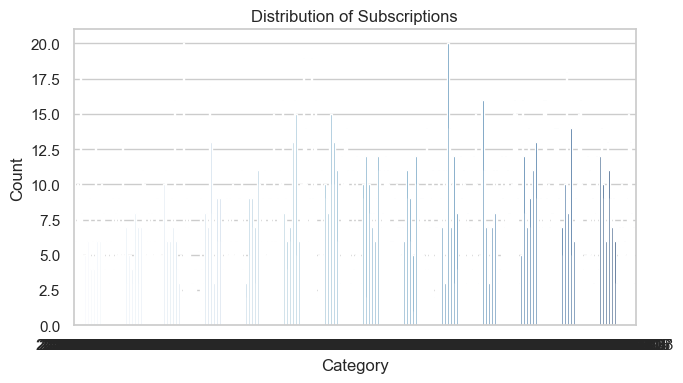

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set a clean plot style
sns.set_theme(style='whitegrid')

# 1. Check the distribution of subscription plans
plt.figure(figsize=(7, 4))
# Note: If your column is named slightly differently, change 'Subscription_Type' to match your column name
sns.countplot(data=df, x=df.columns[1], palette='Blues')
plt.title('Distribution of Subscriptions')
plt.xlabel('Category')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

In [13]:
# Identify if there is a cancellation date column
# If a cancellation date exists, the customer churned (1), otherwise active (0)
cancel_col = [col for col in df.columns if 'cancel' in col.lower() or 'end' in col.lower()]

if cancel_col:
    df['Churn'] = df[cancel_col[0]].notnull().astype(int)
    print("Churn summary (1 = Left, 0 = Active):")
    print(df['Churn'].value_counts())
    print("\nChurn Percentage:")
    print(df['Churn'].value_counts(normalize=True) * 100)

Churn summary (1 = Left, 0 = Active):
Churn
1    2004
0    1065
Name: count, dtype: int64

Churn Percentage:
Churn
1    65.298143
0    34.701857
Name: proportion, dtype: float64


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. Select numeric features or convert simple categories
X = df.select_dtypes(include=['int64', 'float64']).copy()

# Remove the target column from features
if 'Churn' in X.columns:
    X = X.drop(columns=['Churn'])

# Drop customer ID columns if present
for id_col in [col for col in X.columns if 'id' in col.lower()]:
    X = X.drop(columns=[id_col])

# Fill missing values with 0
X = X.fillna(0)

# Define target y
y = df['Churn']

# 2. Split data: 80% to train the model, 20% to test it
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# 3. Train a basic Logistic Regression model
model = LogisticRegression(max_iter=500)
model.fit(X_train, y_train)

# 4. Predict on the test data and calculate accuracy
predictions = model.predict(X_test)
accuracy = accuracy_score(y_test, predictions)

print(f"Model Accuracy: {round(accuracy * 100, 2)}%")

Model Accuracy: 66.78%


In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Prepare features: drop ID and target columns
drop_cols = ['Churn'] + [c for c in df.columns if 'id' in c.lower() or 'date' in c.lower()]
X_all = df.drop(columns=[col for col in drop_cols if col in df.columns])

# 2. Convert text/categorical columns into numbers (One-Hot Encoding)
X_all_encoded = pd.get_dummies(X_all, drop_first=True)
y_all = df['Churn']

# 3. Train-Test Split (80% train, 20% test)
X_tr, X_te, y_tr, y_te = train_test_split(X_all_encoded, y_all, test_size=0.20, random_state=42)

# 4. Train a Random Forest model
rf_model = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42)
rf_model.fit(X_tr, y_tr)

# 5. Check updated accuracy
rf_preds = rf_model.predict(X_te)
rf_acc = accuracy_score(y_te, rf_preds)

print(f"Updated Model Accuracy: {round(rf_acc * 100, 2)}%")
print("\nDetailed Performance:")
print(classification_report(y_te, rf_preds))

Updated Model Accuracy: 66.78%

Detailed Performance:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       204
           1       0.67      1.00      0.80       410

    accuracy                           0.67       614
   macro avg       0.33      0.50      0.40       614
weighted avg       0.45      0.67      0.53       614



C:\Users\vansh\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\vansh\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\vansh\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [16]:
print(df.columns.tolist())

['customer_id', 'created_date', 'canceled_date', 'subscription_cost', 'subscription_interval', 'was_subscription_paid', 'Churn']


In [17]:
print(X_all_encoded.shape)
print(X_all_encoded.head(2))

(3069, 1)
   subscription_cost
0                 39
1                 39


In [18]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, roc_auc_score

# 1. Feature Engineering from dates
df['created_date'] = pd.to_datetime(df['created_date'])
df['signup_year'] = df['created_date'].dt.year
df['signup_month'] = df['created_date'].dt.month
df['signup_dayofweek'] = df['created_date'].dt.dayofweek

# 2. Select features to train on (ignore raw dates and IDs)
features = [
    'subscription_cost', 
    'subscription_interval', 
    'was_subscription_paid', 
    'signup_year', 
    'signup_month', 
    'signup_dayofweek'
]

X = df[features].copy()
y = df['Churn']

# 3. Handle missing values & One-Hot Encoding for text columns
X['subscription_cost'] = X['subscription_cost'].fillna(X['subscription_cost'].median())
X = pd.get_dummies(X, drop_first=True)

# 4. Train-Test Split (80% train, 20% test) with stratified sampling
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 5. Train Random Forest with balanced weights (handles class imbalance)
rf_model = RandomForestClassifier(n_estimators=150, max_depth=5, class_weight='balanced', random_state=42)
rf_model.fit(X_train, y_train)

# 6. Evaluate
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

print(f"Accuracy: {round(accuracy_score(y_test, y_pred) * 100, 2)}%")
print(f"ROC-AUC Score: {round(roc_auc_score(y_test, y_prob), 4)}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 72.96%
ROC-AUC Score: 0.7887

Classification Report:
              precision    recall  f1-score   support

           0       0.59      0.75      0.66       213
           1       0.84      0.72      0.78       401

    accuracy                           0.73       614
   macro avg       0.72      0.73      0.72       614
weighted avg       0.75      0.73      0.74       614



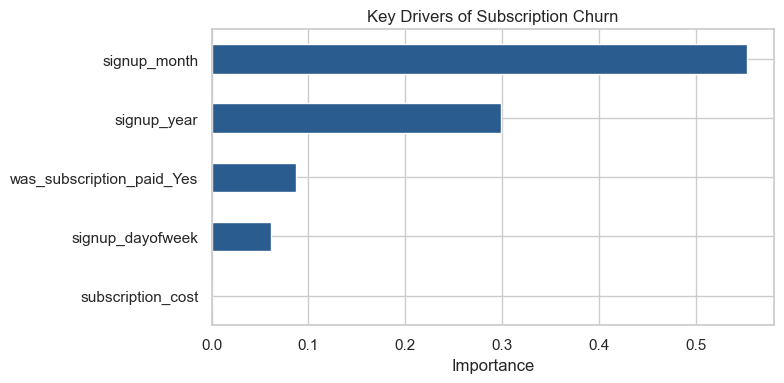

In [19]:
import matplotlib.pyplot as plt

# Plot Feature Importance
feat_importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 4))
feat_importances.plot(kind='barh', color='#2b5c8f')
plt.title('Key Drivers of Subscription Churn')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

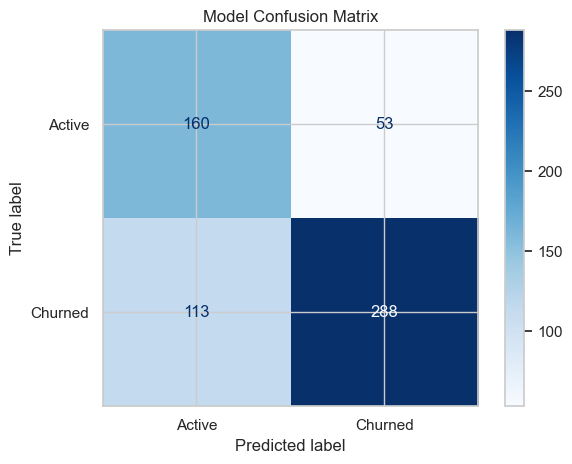

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Generate Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Active', 'Churned'])

disp.plot(cmap='Blues')
plt.title('Model Confusion Matrix')
plt.tight_layout()
plt.savefig('confusion_matrix.png')
plt.show()